In [12]:
import pandas as pd

# Carga dos datasets estruturados da Olist
df_pedidos = pd.read_csv('olist_orders_dataset.csv')
df_pagamentos = pd.read_csv('olist_order_payments_dataset.csv')
df_clientes = pd.read_csv('olist_customers_dataset.csv')


In [13]:
# Unificação das tabelas e filtro por pedidos entregues (faturamento real)
df_consolidado = pd.merge(df_pedidos, df_pagamentos, on='order_id', how='inner')
df_vendas_sucesso = df_consolidado[df_consolidado['order_status'] == 'delivered']
df_vendas_completo = pd.merge(df_vendas_sucesso, df_clientes, on='customer_id', how='inner')


In [18]:
# Cálculo de métricas macro financeiras
faturamento_total = df_vendas_completo['payment_value'].sum()
ticket_medio = df_vendas_completo['payment_value'].mean()

print(f"Faturamento Total: R$ {faturamento_total:,.2f}")
print(f"Ticket Medio por Pedido: R$ {ticket_medio:,.2f}\n")

# Consolidação do faturamento acumulado por ID único de cliente (Análise VIP)
clientes_vip = df_vendas_completo.groupby('customer_unique_id')['payment_value'].sum().reset_index()
clientes_vip = clientes_vip.sort_values(by='payment_value', ascending=False)
clientes_vip.columns = ['ID_Unico_Cliente', 'Total_Gasto_(R$)']

clientes_vip.head(5)


Faturamento Total: R$ 15,422,461.77
Ticket Medio por Pedido: R$ 153.07



,ID_Unico_Cliente,Total_Gasto_(R$)
3724,0a0a92112bd4c708ca5fde585afaa872,13664.08
79635,da122df9eeddfedc1dc1f5349a1a690c,7571.63
43168,763c8b1c9c68a0229c42c9fc6f662b93,7274.88
80462,dc4802a71eae9be1dd28f5d788ceb526,6929.31
25436,459bef486812aa25204be022145caa62,6922.21


In [19]:
# Agrupamento para identificar a receita por estado
faturamento_por_estado = df_vendas_completo.groupby('customer_state')['payment_value'].sum().reset_index()
faturamento_por_estado = faturamento_por_estado.sort_values(by='payment_value', ascending=False)
faturamento_por_estado.columns = ['Estado', 'Faturamento Total (R$)']

faturamento_por_estado.head(5)


,Estado,Faturamento Total (R$)
25,SP,5770266.19
18,RJ,2055690.45
10,MG,1819277.61
22,RS,861802.40
17,PR,781919.55


C:\Users\letic\AppData\Local\Temp\ipykernel_13716\501911174.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


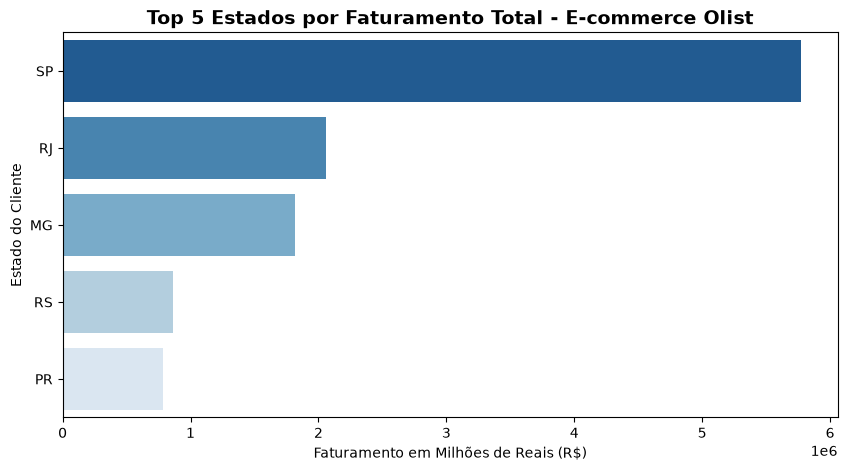

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual do gráfico de faturamento por estado
plt.figure(figsize=(10, 5))
sns.barplot(
    x='Faturamento Total (R$)', 
    y='Estado', 
    data=faturamento_por_estado.head(5), 
    palette='Blues_r'
)

plt.title('Top 5 Estados por Faturamento Total - E-commerce Olist', fontsize=14, fontweight='bold')
plt.xlabel('Faturamento em Milhões de Reais (R$)')
plt.ylabel('Estado do Cliente')
plt.show()


In [16]:
# Tratamento de datas para análise de lead time logístico
df_vendas_completo['order_purchase_timestamp'] = pd.to_datetime(df_vendas_completo['order_purchase_timestamp'])
df_vendas_completo['order_delivered_customer_date'] = pd.to_datetime(df_vendas_completo['order_delivered_customer_date'])
df_vendas_completo['order_estimated_delivery_date'] = pd.to_datetime(df_vendas_completo['order_estimated_delivery_date'])

# Cálculo do tempo de transporte e flags de atraso
df_vendas_completo['dias_para_entregar'] = (df_vendas_completo['order_delivered_customer_date'] - df_vendas_completo['order_purchase_timestamp']).dt.days
df_vendas_completo['houve_atraso'] = (df_vendas_completo['order_delivered_customer_date'] > df_vendas_completo['order_estimated_delivery_date']).astype(int)

# Consolidação de indicadores de eficiência por região
analise_logistica = df_vendas_completo.groupby('customer_state').agg(
    Tempo_Medio_Entrega_Dias=('dias_para_entregar', 'mean'),
    Taxa_Atraso_Percentual=('houve_atraso', 'mean')
).reset_index()

analise_logistica['Taxa_Atraso_Percentual'] = analise_logistica['Taxa_Atraso_Percentual'] * 100
analise_logistica = analise_logistica.sort_values(by='Tempo_Medio_Entrega_Dias', ascending=False)

# Exibe os 5 estados com maior lentidão na entrega
analise_logistica.head(5)


,customer_state,Tempo_Medio_Entrega_Dias,Taxa_Atraso_Percentual
21,RR,28.975610,12.195122
3,AP,26.652174,4.347826
2,AM,26.139073,3.973510
1,AL,24.194647,24.330900
13,PA,23.277268,12.334353
